# Q1.
**With bias**

*In practice, linear regression always comes with bias*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Xb = np.array([[1, 2],
               [0,6],
               [1,0],
               [0,5],
               [1,7]])
y = np.array([[1],
              [2],
              [3],
              [4],
              [5]])
print(Xb)

[[1 2]
 [0 6]
 [1 0]
 [0 5]
 [1 7]]


In [2]:
wb = np.linalg.inv(Xb.T@Xb)@Xb.T@y
print(wb)

[[1.55172414]
 [0.48275862]]


**Without bias**

*Unusual case, just to demonstrate the effect of bias here*

In [45]:
X = np.array([[-10],[-8],[-3],[-1],[2],[8]])
w = np.linalg.inv(X.T@X)@X.T@y
print(w)

[[-0.35123967]]


**plot two linear regression lines**

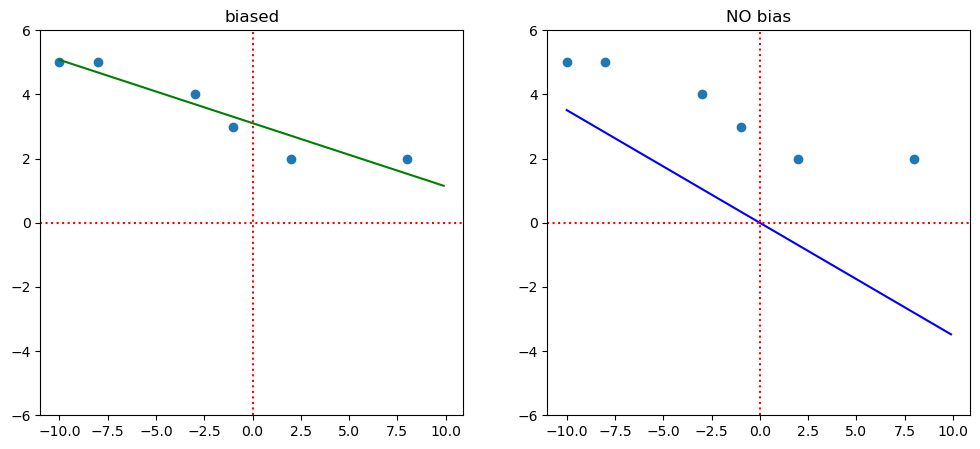

In [46]:
xx = np.arange(-10,10,0.1)
yyb = xx*wb[1][0] + wb[0][0]
yy = xx*w[0][0]

fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].scatter(X, y)
ax[0].plot(xx, yyb, 'green')
ax[0].axhline(0, color='red', linestyle = ':')
ax[0].axvline(0, color='red', linestyle = ':')
ax[0].set_ylim([-6,6])
ax[0].set_title('biased')

ax[1].scatter(X, y)
ax[1].plot(xx,yy, 'blue')
ax[1].axhline(0, color='red', linestyle = ':')
ax[1].axvline(0, color='red', linestyle = ':')
ax[1].set_ylim([-6,6])
ax[1].set_title('NO bias')

plt.show()

# Q2.
**Without bias**

*Again, just to demonstrate even-determined system through no-bias, this is uncommon*

In [5]:
X = np.array([[1,0,1],
              [2,-1,1],
              [1,1,5]])
y = np.array([[1],
              [2],
              [3]])

In [6]:
w = np.linalg.inv(X)@y
print(w)

[[ 0.33333333]
 [-0.66666667]
 [ 0.66666667]]


In [7]:
X_pred = np.array([[-1,2,8],[1,5,-1]])
y_pred = X_pred@w
print(y_pred)

[[ 3.66666667]
 [-3.66666667]]


**with bias**

## Trick 1: `np.concatenate()`

**Steps**:
1. Generate 1's column vector
2. concatenate this column to your X

In [8]:
one_column = np.ones([len(X),1])
print(one_column)

[[1.]
 [1.]
 [1.]]


In [9]:
Xb = np.concatenate((one_column, X), axis=1)
print(Xb)

[[ 1.  1.  0.  1.]
 [ 1.  2. -1.  1.]
 [ 1.  1.  1.  5.]]


In [10]:
wb = Xb.T@np.linalg.inv(Xb@Xb.T) @ y   # Training through right inverse
print(wb)

[[-0.14285714]
 [ 0.52380952]
 [-0.47619048]
 [ 0.61904762]]


***Note**: For prediction, adding 1's column in feature to allow trained bias*

In [11]:
Xb_pred = np.concatenate((np.ones([len(X_pred),1]), X_pred), axis=1)
yb_pred = Xb_pred@wb
print(yb_pred)

[[ 3.33333333]
 [-2.61904762]]


# Q3

In [12]:
X = np.array([[36],[28],[35],[39],[30],[30],[31],[38],[36],[38],[29],[26]])
y = np.array([[31],[29],[34],[35],[29],[30],[30],[38],[34],[33],[29],[26]])

Add the bias 1's column through `np.concatenate()`

In [13]:
Xb = np.concatenate((np.ones([len(X),1]),X), axis=1)
print(Xb)

[[ 1. 36.]
 [ 1. 28.]
 [ 1. 35.]
 [ 1. 39.]
 [ 1. 30.]
 [ 1. 30.]
 [ 1. 31.]
 [ 1. 38.]
 [ 1. 36.]
 [ 1. 38.]
 [ 1. 29.]
 [ 1. 26.]]


In [14]:
wb = np.linalg.inv(Xb.T@Xb)@Xb.T@y
print(wb)
print('Regression formula: y = {:.2f}*x + {:.2f}'.format(wb[1][0], wb[0][0]))

[[9.3       ]
 [0.67272727]]
Regression formula: y = 0.67*x + 9.30


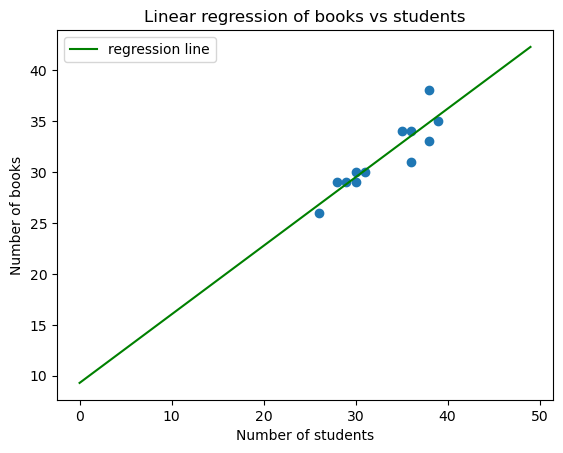

In [15]:
xx = np.arange(0,50,1)
yyb = xx*wb[1][0] + wb[0][0]
plt.scatter(X,y)
plt.plot(xx, yyb, c='green', label='regression line')
plt.xlabel('Number of students')
plt.ylabel('Number of books')
plt.legend()
plt.title('Linear regression of books vs students')
plt.show()

*Predict when $x=30$, the model is reasonable. This is because ML is good at **interpolation***

In [16]:
y_30 = np.array([[1,30]])@wb
print(y_30)

[[29.48181818]]


*Predict when $x=5$, the model is totally off. This is because ML is bad at **extrapolation***

In [17]:
y_5 = np.array([[1,5]])@wb
print(y_5)

[[12.66363636]]


# Q4.

In [18]:
# Out of scope, you can try and play around by yourself

# This function will purge duplicates using pandas.DataFrame.drop_duplicates
# input X: (N,1) column vector
# input y: (N,1) column vector

import pandas as pd
import numpy as np
def purge_duplicate(X,y):
    
    # get Xy DataFrame
    Xy = np.concatenate((X,y),axis=1)
    df = pd.DataFrame(Xy, columns=['X','y'])
    '''
    drop duplicated rows, in this case, it removes duplicate rows based on all columns.
    In another words, if all element within a row are all identical to another row, this row will be purged
    '''
    df_new = df.drop_duplicates()
    
    # Retrieve new X and y
    Xn_1d = np.array(df_new['X'])
    yn_1d = np.array(df_new['y'])
    
    # reshape dimensions, make sure outputs have shape of (M,1)
    Xn = Xn_1d.reshape(-1,1)
    yn = yn_1d.reshape(-1,1)
    
    return Xn,yn

**Train the model using all data**

In [19]:
X = np.array([[36],[26],[35],[39],[26],[30],[31],[38],[36],[38],[26],[26]])
y = np.array([[31],[20],[34],[35],[20],[30],[30],[38],[34],[33],[20],[20]])

Xb = np.concatenate((np.ones([len(X),1]),X),axis=1)
wb = np.linalg.inv(Xb.T@Xb)@Xb.T@y
print('Regression formula: y = {:.2f}*x + {:.2f}'.format(wb[1][0], wb[0][0]))

Regression formula: y = 1.21*x + -10.41


In [20]:
y_30 = np.array([[1,30]])@wb
print(y_30)

[[26.01772764]]


**purge duplicates and re-train the model**

In [21]:
Xn, yn = purge_duplicate(X,y)
print(Xn)

[[36]
 [26]
 [35]
 [39]
 [30]
 [31]
 [38]
 [36]
 [38]]


In [22]:
Xnb = np.concatenate((np.ones([len(Xn),1]),Xn),axis=1)
wnb = np.linalg.inv(Xnb.T@Xnb)@Xnb.T@yn
print('Post-purge regression formula: y = {:.2f}*x + {:.2f}'.format(wnb[1][0], wnb[0][0]))

yn_30 = np.array([[1,30]])@wnb
print(yn_30)

Post-purge regression formula: y = 1.03*x + -3.56
[[27.22077922]]


**Pre-purge model will be closer to the duplicated point to reduce total error (SSE)**

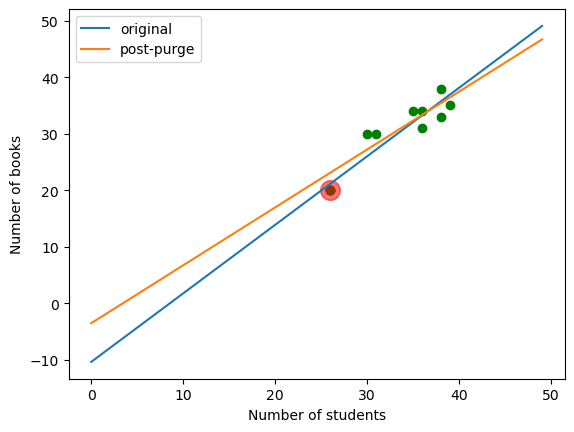

In [23]:
xx = np.arange(0,50,1)
yyb = xx*wb[1][0] + wb[0][0]
yynb = xx*wnb[1][0] + wnb[0][0]

plt.scatter(X,y, color='green')
plt.scatter(26,20, alpha=.55, s=200,color='red', edgecolor='red')

plt.plot(xx, yyb, label='original')
plt.plot(xx, yynb, label='post-purge')

plt.xlabel('Number of students')
plt.ylabel('Number of books')
plt.legend()
plt.show()

# Q5.
**load data**

In [24]:
import pandas as pd
df = pd.read_csv('/Users/yutongdu/Downloads/government-expenditure-on-education.csv')
print(df)

    year  recurrent_expenditure_total
0   1981                       712732
1   1982                       983751
2   1983                      1107113
3   1984                      1272559
4   1985                      1388186
5   1986                      1280364
6   1987                      1352551
7   1988                      1461858
8   1989                      1619760
9   1990                      1794522
10  1991                      2356794
11  1992                      2043178
12  1993                      2210329
13  1994                      2486241
14  1995                      2682419
15  1996                      2997158
16  1997                      3347775
17  1998                      3167425
18  1999                      3256874
19  2000                      4276896
20  2001                      4766584
21  2002                      4824395
22  2003                      4996791
23  2004                      4974724
24  2005                      5215299
25  2006    

In [25]:
expenditureList = df ['recurrent_expenditure_total'].to_list()
yearList = df['year'].to_list()

## Trick 2: `transpose([[1]*len(X), X])`

**Steps**:
1. add 1's list as element
2. dump the list to numpy array
3. transpose the array

*Note: this method works for **1-d** feature only!!!*

In [26]:
m_list = [[1]*len(yearList), yearList]
X = np.array(m_list).T
print(X)

[[   1 1981]
 [   1 1982]
 [   1 1983]
 [   1 1984]
 [   1 1985]
 [   1 1986]
 [   1 1987]
 [   1 1988]
 [   1 1989]
 [   1 1990]
 [   1 1991]
 [   1 1992]
 [   1 1993]
 [   1 1994]
 [   1 1995]
 [   1 1996]
 [   1 1997]
 [   1 1998]
 [   1 1999]
 [   1 2000]
 [   1 2001]
 [   1 2002]
 [   1 2003]
 [   1 2004]
 [   1 2005]
 [   1 2006]
 [   1 2007]
 [   1 2008]
 [   1 2009]
 [   1 2010]
 [   1 2011]
 [   1 2012]
 [   1 2013]
 [   1 2014]
 [   1 2015]
 [   1 2016]
 [   1 2017]
 [   1 2018]
 [   1 2019]]


In [27]:
y = np.array(expenditureList)
print(y)

[  712732   983751  1107113  1272559  1388186  1280364  1352551  1461858
  1619760  1794522  2356794  2043178  2210329  2486241  2682419  2997158
  3347775  3167425  3256874  4276896  4766584  4824395  4996791  4974724
  5215299  6351717  6785625  7476521  7837909  8998709  9697793  9637312
 10664868 10712445 11235741 11812194 12079538 12429006 12039000]


- y.shape: (m, ) --> 1-d array
- w.shape: (2, ) --> 1-d array

In [28]:
w = np.linalg.inv(X.T @ X) @ X.T @ y
print(w)

[-6.4843247e+08  3.2683591e+05]


**Data visualization**

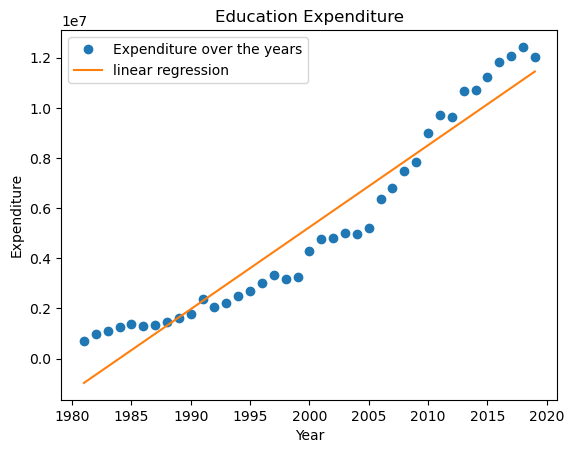

In [29]:
y_line = X@w
# y_line = X.dot(w)

plt.plot(yearList, expenditureList, 'o', label = 'Expenditure over the years')
plt.plot(yearList, y_line, label='linear regression')
plt.xlabel('Year' )
plt.ylabel('Expenditure')
plt.title('Education Expenditure')
plt.legend()
plt.show()

**Prediction**

In [30]:
y_predict = np.array([1, 2021])@w
print(y_predict)

12102904.270636732


# Q6.

In [31]:
import pandas as pd

## Cool way to load data: directly read from URL
# wine = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",sep=';')

wine = pd.read_csv('./Data/winequality-red.csv')   ## Your own path to the data file
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [32]:
print(wine.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1599.000000       1599.000000  1599.000000     1599.000000   
mean        8.319637          0.527821     0.270976        2.538806   
std         1.741096          0.179060     0.194801        1.409928   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.420000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  1599.000000          1599.000000           1599.000000  1599.000000   
mean      0.087467            15.874922             46.467792     0.996747   
std       0.047065            10.460157             32.895324     0.001887   
min       0.012000             1.000000         

In [33]:
y = wine['quality']
x = wine.drop('quality',axis = 1)

## Trick 3: `np.hstack()`

**Steps**:
1. Generate 1's column vector
2. stack arrays in sequence horizontally (column wise)

In [34]:
x0 = np.ones((len(y),1))
X = np.hstack((x0,x))
print(X)

[[ 1.     7.4    0.7   ...  3.51   0.56   9.4  ]
 [ 1.     7.8    0.88  ...  3.2    0.68   9.8  ]
 [ 1.     7.8    0.76  ...  3.26   0.65   9.8  ]
 ...
 [ 1.     6.3    0.51  ...  3.42   0.75  11.   ]
 [ 1.     5.9    0.645 ...  3.57   0.71  10.2  ]
 [ 1.     6.     0.31  ...  3.39   0.66  11.   ]]


**Train-test split through `train_test_split()`**

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=10/16, random_state=42)

In [36]:
w = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train 
print(w)

[ 1.56653120e+01  2.02022025e-02 -1.32957912e+00 -2.75697912e-01
  3.59641867e-02 -2.85455501e+00  3.05169418e-03 -1.98726495e-03
 -1.31461406e+01  3.94467313e-02  8.50682505e-01  3.03777602e-01]


**use `sklearn.metrics.mean_squared_error()` to find MSE**

In [37]:
from sklearn.metrics import mean_squared_error

y_pred = X_test @ w
print(y_pred)

MSE = mean_squared_error(y_test, y_pred)
print(MSE)

[5.2675556  5.13046793 5.52503507 5.42851331 5.73799057 5.31211294
 5.10240548 5.03023165 5.70787398 5.75122389 5.94955151 5.22621288
 5.55580098 5.18793186 5.45500794 6.48748923 5.17382581 5.53949143
 6.52107868 5.18872931 5.42639684 5.12153281 6.06743069 6.4541621
 5.30922147 5.47185635 6.45983762 5.39304052 5.30801634 6.21300881
 5.24396311 5.56438326 5.72578007 5.2198     5.4761835  4.9887104
 6.2253135  5.73796614 5.41870523 6.18136864 5.2860522  5.21980807
 6.09010926 5.15810962 5.61562304 5.75292187 6.41882267 5.43471352
 5.08467145 5.51913047 5.24240823 4.57016092 5.50512637 6.60731506
 5.01313425 4.87097245 6.01077705 5.49914038 5.90338243 5.27524261
 5.60830682 5.90238954 5.2289863  5.37312001 6.48322215 5.45517093
 6.32191124 5.34409014 6.5489992  5.34506883 6.55159225 4.63552616
 5.74570188 5.88957327 6.20249112 5.13108345 7.03166345 5.97565862
 6.25370338 6.63160164 5.42468366 6.43956222 5.43058679 5.67302456
 5.79321948 6.34912072 5.31712192 5.92866863 6.30912513 5.239909

Or, manually:

In [38]:
y_pred = X_test @ w
MSE = ((y_pred - y_test)**2).mean()
print(MSE)

0.4666421205498303


# Q9.
**Multiple outputs**: one label as a column

In [39]:
X = np.array([[1, 3, -1, 0], 
              [1, 5, 1, 2], 
              [1, 9, -1, 3], 
              [1, -6, 7, 2], 
              [1, 3, -2, 0]])

Y = np.array([[1, -1], 
              [-1, 0], 
              [1, 2], 
              [0, 3], 
              [1, -2]])

W = np.linalg.inv(X.T @ X) @ X.T @ Y
print(W)

[[ 1.14668974 -0.95997404]
 [-0.630463   -0.33427088]
 [-1.10601471 -0.24426655]
 [ 1.3595846   1.77953267]]


In [40]:
newX = np.array([[1, 8, 0, 2]])
newY = newX@W
print(newY)

[[-1.17784509 -0.07507572]]


# Reference code: linear (polynomial, ridge) regression
*Note: This function adds 1's bias column for you!*

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

def PolyReg(X_train: np.ndarray, 
            y_train: np.ndarray, 
            X_test: np.ndarray = None, 
            y_test: np.ndarray = None, 
            n: int = 1, 
            lmd: float = 0.0):
    '''
    Perform linear regression or polynomial regression, with or without L2 regularization (ridge regression)

    Parameter
    ---
    n : int
        order of regression (default n=1: linear regression)
    X_train : np.ndarray
        raw training features (d*m), one row is one sample
    y_train : np.ndarray
        raw training labels (n*m), one row is one sample
    X_test : np.ndarray
        raw test features
    y_test : np.ndarray
        raw test labels
    lmd : float
        L2 regularization (ridge)
    '''
    poly = PolynomialFeatures(n)
    Ptr = poly.fit_transform(X_train)

    if n == 1:
        print('Performing linear regression...')
    else:
        print(f'Performing polynomial regression with order {n}...')
    
    if lmd == 0.0:
        print('No regularization')
    else:
        print(f'Performing ridge regression with lambda = {lmd}...')

    if Ptr.shape[0] > Ptr.shape[1]:
        # if tall, use primal
        w = np.linalg.inv(Ptr.T @ Ptr + lmd*np.identity(Ptr.shape[1])) @ Ptr.T @ y_train
    else:
        # if wide, use dual
        w = Ptr.T @ np.linalg.inv(Ptr @ Ptr.T + lmd*np.identity(Ptr.shape[0])) @ y_train
        
    # use trained w to see the MSE of training data
    y_train_hat = Ptr@w
    MSE_train = mean_squared_error(y_train, y_train_hat)

    MSE_test = None
    if X_test is not None and y_test is not None:
        Pts = poly.transform(X_test)
        # use trained w to make predictions based on X_test, calculate the MSE of prediction
        y_test_pred = Pts@w
        MSE_test = mean_squared_error(y_test, y_test_pred)
    
    return w, MSE_train, MSE_test

In [42]:
X = np.array([[-10],
              [-8],
              [-3],
              [-1],
              [2],
              [8]])

y = np.array([[5],
              [5],
              [4],
              [3],
              [2],
              [2]])

w, MSE_train, MSE_test = PolyReg(X, y)
print('w = \n', w)

Performing linear regression...
No regularization
w = 
 [[ 3.10550459]
 [-0.19724771]]
